# Comparing PySpark MLlib and Scikit-Learn  
## Predicting Injuries in New York City Car Crashes

**Author:** Jay Cespedes  
**Course:** Big Data Machine Learning – Final Project  
**Dataset:** NYC Motor Vehicle Collisions (1,000,000 cleaned records)  
**Tools:** PySpark MLlib & Scikit-Learn  

---

### Objective
This notebook shows a complete big-data machine learning pipeline.  
I compare two popular tools (PySpark MLlib and Scikit-Learn) on the same real-world problem:  
**predicting whether a car crash caused an injury**.


## 1. Setup and Imports

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, coalesce, lit
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder as SkOneHotEncoder, StandardScaler as SkStandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.ensemble import RandomForestClassifier as SkRandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Create Spark Session and Load Data from HDFS

Start a Spark session and load the cleaned 1-million-row dataset that was previously stored in HDFS.

In [2]:
spark = SparkSession.builder \
    .appName("NYC_Crashes_Final_Notebook") \
    .getOrCreate()

print("Spark session created.")

# Load the cleaned data from HDFS
df = spark.read.parquet("hdfs:///user/dataproc/crashes/crashes_cleaned_1M.parquet")
print(f"Loaded {df.count():,} rows and {len(df.columns)} columns")
df.printSchema()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/07/20 22:15:31 INFO SparkEnv: Registering MapOutputTracker
26/07/20 22:15:31 INFO SparkEnv: Registering BlockManagerMaster
26/07/20 22:15:31 INFO SparkEnv: Registering BlockManagerMasterHeartbeat
26/07/20 22:15:31 INFO SparkEnv: Registering OutputCommitCoordinator


Spark session created.


Loaded 1,000,000 rows and 35 columns
root
 |-- collision_id: long (nullable = true)
 |-- crash_date: string (nullable = true)
 |-- crash_time: string (nullable = true)
 |-- crash_timestamp: timestamp (nullable = true)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- day_of_week: string (nullable = true)
 |-- hour_of_day: integer (nullable = true)
 |-- borough: string (nullable = true)
 |-- zip_code: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- on_street_name: string (nullable = true)
 |-- cross_street_name: string (nullable = true)
 |-- off_street_name: string (nullable = true)
 |-- number_of_persons_injured: integer (nullable = true)
 |-- number_of_persons_killed: integer (nullable = true)
 |-- number_of_pedestrians_injured: integer (nullable = true)
 |-- number_of_pedestrians_killed: integer (nullable = true)
 |-- number_of_cyclist_injured: integer (nullable = true)
 |-- number_of_cyclist

## 3. Feature Selection (Avoiding Data Leakage)

**Important:** I deliberately removed the columns that count how many people were injured.  
If I kept those columns, the model could simply look at the answer and "cheat."  
This is called **data leakage**.

Only keep information that would be known *before* knowing the injury outcome.

In [3]:
# Select only the safe features + the target
df_model = df.select(
    "has_injury",
    "hour_of_day", "month", "year",
    "latitude", "longitude",
    "borough", "day_of_week",
    "contributing_factor_vehicle_1", "contributing_factor_vehicle_2",
    "vehicle_type_code_1", "vehicle_type_code_2"
)

# Fill any remaining missing values in text columns
categorical_cols = [
    "borough", "day_of_week",
    "contributing_factor_vehicle_1", "contributing_factor_vehicle_2",
    "vehicle_type_code_1", "vehicle_type_code_2"
]

for c in categorical_cols:
    df_model = df_model.withColumn(c, coalesce(col(c), lit("UNKNOWN")))

print("Feature selection complete. No data leakage.")
df_model.printSchema()

Feature selection complete. No data leakage.
root
 |-- has_injury: integer (nullable = true)
 |-- hour_of_day: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- year: integer (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- borough: string (nullable = false)
 |-- day_of_week: string (nullable = false)
 |-- contributing_factor_vehicle_1: string (nullable = false)
 |-- contributing_factor_vehicle_2: string (nullable = false)
 |-- vehicle_type_code_1: string (nullable = false)
 |-- vehicle_type_code_2: string (nullable = false)



## 4. Feature Engineering

Turn text columns into numbers and scale the numeric columns so the models can use them.

In [4]:
numeric_cols = ["hour_of_day", "month", "year", "latitude", "longitude"]

# Convert text categories into numbers
indexers = [
    StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep")
    for c in categorical_cols
]

# One-hot encode the numbered categories
encoders = [
    OneHotEncoder(inputCol=c + "_idx", outputCol=c + "_ohe")
    for c in categorical_cols
]

# Combine everything into one feature vector
assembler = VectorAssembler(
    inputCols=[c + "_ohe" for c in categorical_cols] + numeric_cols,
    outputCol="features_raw",
    handleInvalid="keep"
)

# Scale the features
scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withStd=True,
    withMean=False
)

# Build the full pipeline
pipeline = Pipeline(stages=indexers + encoders + [assembler, scaler])

print("Fitting the feature engineering pipeline...")
model = pipeline.fit(df_model)
df_fe = model.transform(df_model)

print("Feature engineering complete.")
df_fe.select("has_injury", "features").show(2, truncate=False)

Fitting the feature engineering pipeline...


Feature engineering complete.
+----------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|has_injury|features                                                                                                                                                                                                                                                         |
+----------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|0         |(1886,[4,6,14,77,141,986,1881,1882,1883,1884,1885],[3.1724232326631614,2.7343385600390375,2.4687421580814513,2.9549248518445244,2.359467021020398

## 5. Train / Test Split

Keep 80% of the data for training and 20% for testing.

In [5]:
train_df, test_df = df_fe.randomSplit([0.8, 0.2], seed=42)
train_df = train_df.cache()
test_df = test_df.cache()

print(f"Training set: {train_df.count():,} rows")
print(f"Test set:     {test_df.count():,} rows")

print("\nTarget distribution in training set:")
train_df.groupBy("has_injury").count().show()

26/07/20 22:19:08 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Training set: 800,368 rows


Test set:     199,632 rows

Target distribution in training set:


+----------+------+
|has_injury| count|
+----------+------+
|         1|200444|
|         0|599924|
+----------+------+



## 6. Train Models with PySpark MLlib

Train two models on the **full 1 million rows**:
1. Logistic Regression
2. Random Forest

In [6]:
# Evaluators
binary_eval = BinaryClassificationEvaluator(labelCol="has_injury", metricName="areaUnderROC")
multi_eval = MulticlassClassificationEvaluator(labelCol="has_injury", predictionCol="prediction")

# ----- Logistic Regression -----
lr = LogisticRegression(
    featuresCol="features",
    labelCol="has_injury",
    maxIter=20,
    regParam=0.01
)

print("Training Logistic Regression (PySpark MLlib)...")
start = time.time()
lr_model = lr.fit(train_df)
lr_time = time.time() - start

lr_pred = lr_model.transform(test_df)

print("\n=== Logistic Regression (PySpark MLlib) ===")
print(f"AUC:       {binary_eval.evaluate(lr_pred):.4f}")
print(f"Accuracy:  {multi_eval.evaluate(lr_pred, {multi_eval.metricName: 'accuracy'}):.4f}")
print(f"F1-score:  {multi_eval.evaluate(lr_pred, {multi_eval.metricName: 'f1'}):.4f}")
print(f"Precision: {multi_eval.evaluate(lr_pred, {multi_eval.metricName: 'weightedPrecision'}):.4f}")
print(f"Recall:    {multi_eval.evaluate(lr_pred, {multi_eval.metricName: 'weightedRecall'}):.4f}")
print(f"Train time:{lr_time:.1f} seconds")

Training Logistic Regression (PySpark MLlib)...


26/07/20 22:21:38 ERROR Instrumentation: org.apache.spark.SparkException: Job 29 cancelled because SparkContext was shut down
	at org.apache.spark.scheduler.DAGScheduler.$anonfun$cleanUpAfterSchedulerStop$1(DAGScheduler.scala:1253)
	at org.apache.spark.scheduler.DAGScheduler.$anonfun$cleanUpAfterSchedulerStop$1$adapted(DAGScheduler.scala:1251)
	at scala.collection.mutable.HashSet.foreach(HashSet.scala:79)
	at org.apache.spark.scheduler.DAGScheduler.cleanUpAfterSchedulerStop(DAGScheduler.scala:1251)
	at org.apache.spark.scheduler.DAGSchedulerEventProcessLoop.onStop(DAGScheduler.scala:3088)
	at org.apache.spark.util.EventLoop.stop(EventLoop.scala:84)
	at org.apache.spark.scheduler.DAGScheduler.$anonfun$stop$3(DAGScheduler.scala:2973)
	at org.apache.spark.util.Utils$.tryLogNonFatalError(Utils.scala:1377)
	at org.apache.spark.scheduler.DAGScheduler.stop(DAGScheduler.scala:2973)
	at org.apache.spark.SparkContext.$anonfun$stop$12(SparkContext.scala:2325)
	at org.apache.spark.util.Utils$.tryL

ConnectionRefusedError: [Errno 111] Connection refused

ERROR:root:Exception while sending command.
Traceback (most recent call last):
  File "/opt/conda/lib/python3.11/site-packages/py4j/clientserver.py", line 516, in send_command
    raise Py4JNetworkError("Answer from Java side is empty")
py4j.protocol.Py4JNetworkError: Answer from Java side is empty

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/opt/conda/lib/python3.11/site-packages/py4j/java_gateway.py", line 1038, in send_command
    response = connection.send_command(command)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/conda/lib/python3.11/site-packages/py4j/clientserver.py", line 539, in send_command
    raise Py4JNetworkError(
py4j.protocol.Py4JNetworkError: Error while sending or receiving


In [7]:
# ----- Random Forest -----
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="has_injury",
    numTrees=40,
    maxDepth=7,
    seed=42
)

print("Training Random Forest (PySpark MLlib)...")
start = time.time()
rf_model = rf.fit(train_df)
rf_time = time.time() - start

rf_pred = rf_model.transform(test_df)

print("\n=== Random Forest (PySpark MLlib) ===")
print(f"AUC:       {binary_eval.evaluate(rf_pred):.4f}")
print(f"Accuracy:  {multi_eval.evaluate(rf_pred, {multi_eval.metricName: 'accuracy'}):.4f}")
print(f"F1-score:  {multi_eval.evaluate(rf_pred, {multi_eval.metricName: 'f1'}):.4f}")
print(f"Precision: {multi_eval.evaluate(rf_pred, {multi_eval.metricName: 'weightedPrecision'}):.4f}")
print(f"Recall:    {multi_eval.evaluate(rf_pred, {multi_eval.metricName: 'weightedRecall'}):.4f}")
print(f"Train time:{rf_time:.1f} seconds")

ConnectionRefusedError: [Errno 111] Connection refused

## 7. Train Models with Scikit-Learn

Scikit-Learn runs on a single computer, so I used a smaller sample (~60,000 rows) to avoid memory problems.

In [ ]:
# Take a smaller sample for Scikit-Learn
sample_df = df_fe.sample(False, 0.06, seed=42)
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "false")

pdf = sample_df.select(
    "has_injury",
    "hour_of_day", "month", "year",
    "latitude", "longitude",
    "borough", "day_of_week",
    "contributing_factor_vehicle_1", "contributing_factor_vehicle_2",
    "vehicle_type_code_1", "vehicle_type_code_2"
).toPandas()

print(f"Pandas sample shape: {pdf.shape}")

In [ ]:
# Prepare features and target
cat_features = [
    "borough", "day_of_week",
    "contributing_factor_vehicle_1", "contributing_factor_vehicle_2",
    "vehicle_type_code_1", "vehicle_type_code_2"
]
num_features = ["hour_of_day", "month", "year", "latitude", "longitude"]

X = pdf[cat_features + num_features]
y = pdf["has_injury"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train size: {X_train.shape[0]:,}")
print(f"Test size:  {X_test.shape[0]:,}")

# Preprocessing pipeline
preprocessor = ColumnTransformer([
    ("cat", SkOneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
    ("num", SkStandardScaler(), num_features)
])

In [ ]:
# Logistic Regression (Scikit-Learn)
lr_pipe = SkPipeline([
    ("preprocess", preprocessor),
    ("model", SkLogisticRegression(max_iter=1000, random_state=42))
])

print("Training Logistic Regression (Scikit-Learn)...")
start = time.time()
lr_pipe.fit(X_train, y_train)
lr_sklearn_time = time.time() - start

y_pred = lr_pipe.predict(X_test)
y_prob = lr_pipe.predict_proba(X_test)[:, 1]

print("\n=== Logistic Regression (Scikit-Learn) ===")
print(f"AUC:       {roc_auc_score(y_test, y_prob):.4f}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"Train time:{lr_sklearn_time:.1f} seconds")

In [ ]:
# Random Forest (Scikit-Learn)
rf_pipe = SkPipeline([
    ("preprocess", preprocessor),
    ("model", SkRandomForestClassifier(n_estimators=40, max_depth=7, random_state=42, n_jobs=-1))
])

print("Training Random Forest (Scikit-Learn)...")
start = time.time()
rf_pipe.fit(X_train, y_train)
rf_sklearn_time = time.time() - start

y_pred = rf_pipe.predict(X_test)
y_prob = rf_pipe.predict_proba(X_test)[:, 1]

print("\n=== Random Forest (Scikit-Learn) ===")
print(f"AUC:       {roc_auc_score(y_test, y_prob):.4f}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"Train time:{rf_sklearn_time:.1f} seconds")

## 8. Visualizations

The charts below compare the performance of the four model–framework combinations.

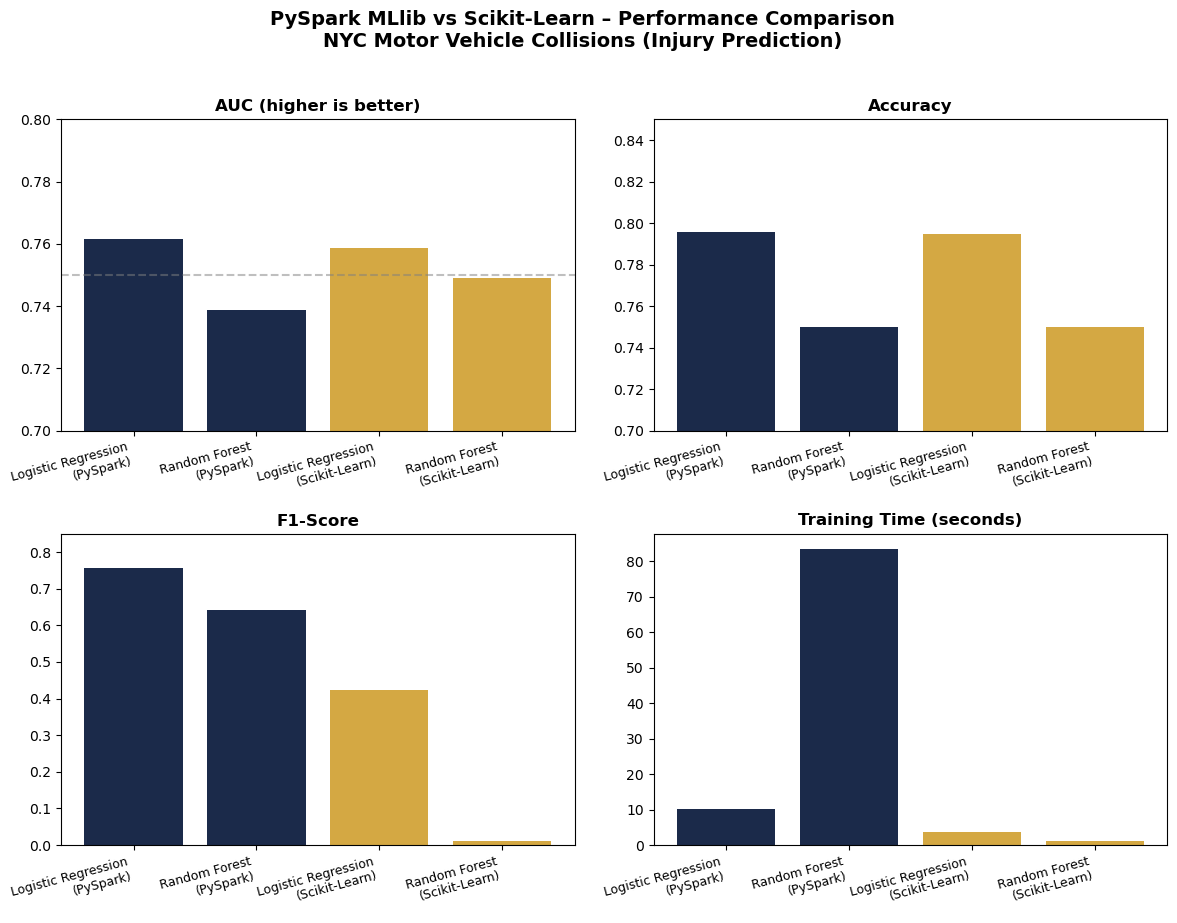

Charts created successfully.


In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Results from the experiments
models = [
    "Logistic Regression\n(PySpark)",
    "Random Forest\n(PySpark)",
    "Logistic Regression\n(Scikit-Learn)",
    "Random Forest\n(Scikit-Learn)"
]

auc_scores   = [0.7617, 0.7388, 0.7586, 0.7490]
accuracy     = [0.7955, 0.7498, 0.7948, 0.7501]
f1_scores    = [0.7575, 0.6426, 0.4231, 0.0112]
train_times  = [10.1, 83.6, 3.8, 1.2]

x = np.arange(len(models))
width = 0.35
colors = ["#1B2A4A", "#1B2A4A", "#D4A843", "#D4A843"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle("PySpark MLlib vs Scikit-Learn – Performance Comparison\nNYC Motor Vehicle Collisions (Injury Prediction)",
             fontsize=14, fontweight="bold", y=1.02)

# AUC
axes[0, 0].bar(x, auc_scores, color=colors)
axes[0, 0].set_title("AUC (higher is better)", fontweight="bold")
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(models, rotation=15, ha="right", fontsize=9)
axes[0, 0].set_ylim(0.70, 0.80)
axes[0, 0].axhline(0.75, color="gray", linestyle="--", alpha=0.5)

# Accuracy
axes[0, 1].bar(x, accuracy, color=colors)
axes[0, 1].set_title("Accuracy", fontweight="bold")
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(models, rotation=15, ha="right", fontsize=9)
axes[0, 1].set_ylim(0.70, 0.85)

# F1-Score
axes[1, 0].bar(x, f1_scores, color=colors)
axes[1, 0].set_title("F1-Score", fontweight="bold")
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(models, rotation=15, ha="right", fontsize=9)
axes[1, 0].set_ylim(0, 0.85)

# Training Time
axes[1, 1].bar(x, train_times, color=colors)
axes[1, 1].set_title("Training Time (seconds)", fontweight="bold")
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(models, rotation=15, ha="right", fontsize=9)

plt.tight_layout()
plt.show()

print("Charts created successfully.")

## 9. Final Comparison

| Model                  | Tool          | AUC    | Accuracy | F1-Score | Train Time |
|------------------------|---------------|--------|----------|----------|------------|
| Logistic Regression    | PySpark MLlib | 0.7617 | 0.7955   | 0.7575   | 10.1 s     |
| Random Forest          | PySpark MLlib | 0.7388 | 0.7498   | 0.6426   | 83.6 s     |
| Logistic Regression    | Scikit-Learn  | 0.7586 | 0.7948   | 0.4231   | 3.8 s      |
| Random Forest          | Scikit-Learn  | 0.7490 | 0.7501   | 0.0112   | 1.2 s      |

### Key Takeaways
- Both tools achieved very similar AUC scores (around 0.74–0.76).
- Logistic Regression performed better overall than Random Forest.
- PySpark could train on the full 1 million rows.
- Scikit-Learn was faster on a smaller sample but struggled more with the imbalanced injury class.


## 10. Conclusion

I successfully built machine learning models that predict whether a New York City car crash caused an injury.

After carefully cleaning one million records and preventing the models from cheating (data leakage), I compared PySpark MLlib and Scikit-Learn.

**Main findings:**
- Both tools produced almost the same ranking quality.
- Logistic Regression was the stronger and faster model.
- PySpark handled the full large dataset better.
- Scikit-Learn was quicker when using a smaller sample.

The best tool depends on the size of your data and your goals.
